# 12 — Santander: agente de uma área → hub → outra área → Databricks

**Este é o notebook principal da demo de 30 minutos.** A implantação e o
ensaio devem ser feitos antes do workshop. O roteiro completo está em
[docs/roteiro.md](../docs/roteiro.md).

Dois agentes **hospedados em Runtime na conta A** usam aplicações Entra
diferentes. A conta central autoriza por usuário, agente e tool. A conta B
publica o MCP Databricks e aplica sua própria Policy; a fonte aplica os
grants reais de cada pessoa. Cada conta tem seu Gateway.

O agente usa um fluxo determinístico para tornar os testes repetíveis.
O notebook 10 continua sendo a referência de Strands/LLM. Não há alteração
do K2: consulte seu [contrato externo](../docs/journey/decisoes.md).

**Padrão:** local; valida Cedar e gera IaC. **Cloud:** opt-in, após os
pré-requisitos do [runbook](../docs/journey/README.md). Resultado local
não comprova OBO nem Unity Catalog.

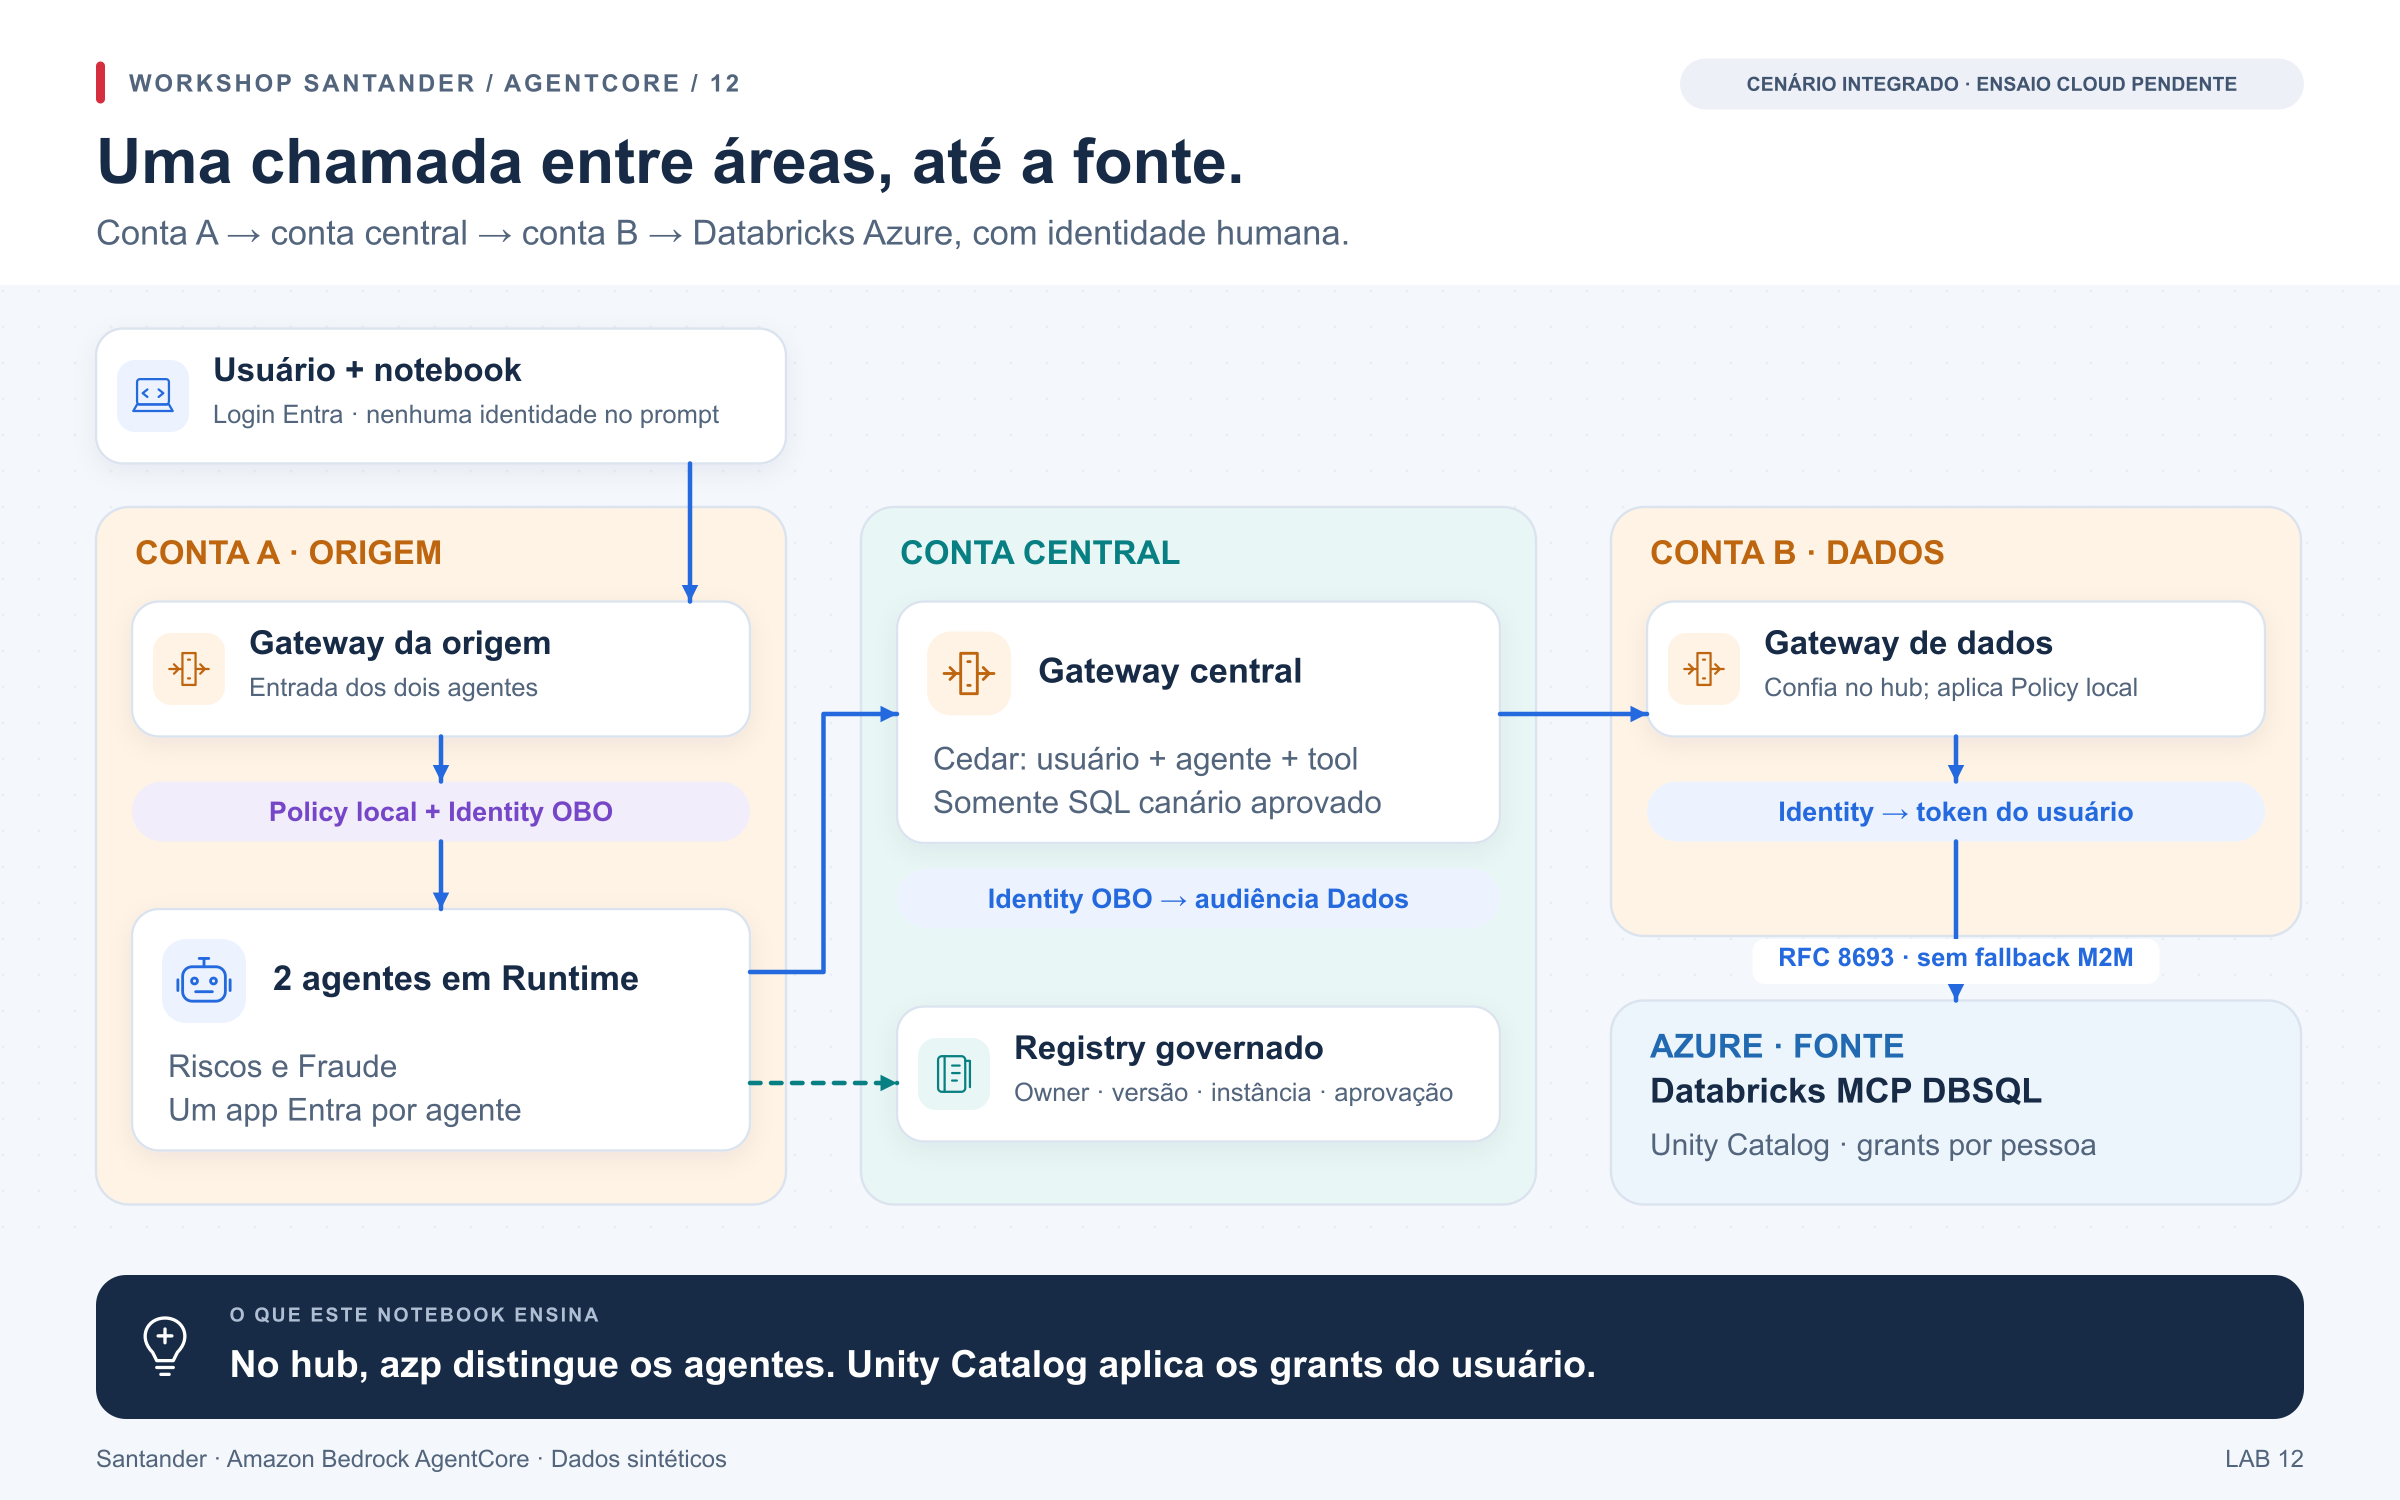

[Ampliar imagem](../docs/journey/arquitetura.png)

## 1. Preparação

Selecione `.venv/bin/python` após `uv sync --frozen --extra banking`.
A célula localiza o projeto e define os controles. `RUN_AWS=False` não usa
perfis AWS. `DEPLOY_PHASE=None` seleciona ensaio; uma fase seleciona
preparação de parâmetros. `RUN_PIPELINE=False` não executa o wrapper.

In [ ]:
import json
import subprocess
from pathlib import Path
from IPython.display import display
from santander_demo.journey.spec import local_matrix
from santander_demo.journey.client import (
    PHASES, load_config, aws_sessions, prepare_phase, preflight, login, run_case,
)
from santander_demo.journey.evidence import acceptance
from santander_demo.governance import local_quota_demo

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
RUN_AWS = False
DEPLOY_PHASE = None
RUN_PIPELINE = False
APPLY_CHANGESET = False
CONFIG_PATH = ROOT / "config/local.journey.json"
LIVE = RUN_AWS and DEPLOY_PHASE is None
rows = []
print("AWS opt-in" if RUN_AWS else "LOCAL: AWS / Entra / Databricks = NOT_RUN")

## 2. Mesma pessoa, agentes diferentes

Vamos executar o mesmo Cedar usado no IaC. Observe:

* Riscos → tool Riscos permite; Fraude → tool Riscos nega.
* Usar a tool Riscos com SQL da tabela Fraude também nega.
* Usuário B passa Policy. Quem nega seu SELECT é o Unity Catalog, no ensaio.
* O Gateway de dados recusa um caller que não seja a plataforma.

A matriz é **LOCAL_CEDAR_ONLY**, sem respostas sintéticas atribuídas à AWS.

In [ ]:
matrix = local_matrix()
display(matrix)
assert len(matrix["cases"]) == 8

## 3. Infraestrutura reproduzível

A célula gera dez templates, sem acessar a nuvem. Há três Gateways,
três engines Policy, dois Runtimes de agente e um Registry central.
Os providers Identity são locais a cada conta; cada agente tem um provider
OBO próprio. Workload identities também pertencem ao CloudFormation.

O modo nativo sem autenticação de cliente do Databricks precisa estar
habilitado pela AWS na conta/região; não basta definir um booleano.
O [sample AWS fixado](../docs/journey/README.md#referências) explica essa
dependência. Não use M2M como substituto silencioso.

In [ ]:
subprocess.run(["uv", "run", "--extra", "banking", "python", "infra/journey/generate.py"], cwd=ROOT, check=True)
templates = sorted(p.name for p in (ROOT / "infra/journey/templates").glob("*.json"))
display(templates)
assert len(templates) == 10

## 4. Preparar fases do IaC ou conferir o ambiente implantado

Primeiro siga o runbook: identidades Entra, federation de **usuários no
nível da conta Databricks**, membership de A/B no workspace, grants
distintos nas tabelas canário e build do artefato.

Para implantar, escolha uma das `PHASES`, habilite `RUN_AWS` e reexecute
desde a preparação. O helper consulta outputs e escreve parâmetros locais.
Revise o comando/change set antes de habilitar sua execução. `registry`
deixa registros pendentes; `approve-registry` é uma promoção separada.
Para ensaiar depois da implantação, volte `DEPLOY_PHASE=None`.

A célula seguinte não implanta nada no padrão. O preflight cloud verifica
contas, audiências, callers, Cedar, targets OBO e fronteiras de Runtime.

In [ ]:
if RUN_AWS:
    config = load_config(CONFIG_PATH)
    sessions = aws_sessions(config)
    if DEPLOY_PHASE is not None:
        plans = prepare_phase(ROOT, config, sessions, DEPLOY_PHASE)
        for plan in plans:
            print(plan["command"])
            if RUN_PIPELINE:
                command = plan["args"] + (["--execute"] if APPLY_CHANGESET else [])
                subprocess.run(command, cwd=ROOT, check=True)
    else:
        environment = preflight(config, sessions)
        print({"preflight": environment["mode"], "invocation_verified": False})
else:
    print({"cloud": "NOT_RUN", "phases": PHASES})

## 5. Usuário A, dois agentes e uma negativa

Faça login como A (OID configurado). As três chamadas começam no
**Gateway de origem**; o código do agente roda na AWS. Primeiro Riscos
lê seu canário, depois Fraude lê o seu. Na terceira chamada, a mesma
pessoa usa o agente Fraude para tentar a capacidade Riscos.

Para as leituras, a prova inclui `current_user()` exato; ter um e-mail na
resposta não basta. A negativa precisa dizer `POLICY_DENY_REPORTED`.
Timeout, ausência de tool ou erro de token não contam como negação Cedar.
O resultado do Registry também aparece, com owner/versão/instância.

In [ ]:
if LIVE:
    token_a = login(config, "a")
    for case, agent, capability in [
        ("a_riscos", "riscos", "riscos"),
        ("a_fraude", "fraude", "fraude"),
        ("a_wrong_agent", "fraude", "riscos"),
    ]:
        row = await run_case(config, environment, token_a, user="a",
                             agent=agent, capability=capability, case=case)
        rows.append(row)
        display(row)
    assert [row["outcome"] for row in rows[-3:]] == [
        "PER_USER_VERIFIED", "PER_USER_VERIFIED", "POLICY_DENY_REPORTED",
    ]
else:
    print("Ensaio A: NOT_RUN — as decisões locais estão na seção 2.")

## 6. Usuário B: Policy permite, Unity Catalog nega

B deve pertencer ao workspace e poder executar a consulta de identidade
no warehouse, mas não possuir SELECT no canário de Riscos. Ambos os
usuários estão na allowlist das três Policies para que a negativa
aconteça **na fonte**.

A célula pede um novo login e verifica seu OID. O agente testa
`current_user()` antes da consulta negada. Ela não remove nem adiciona
grants. Esse estado é preparado pelo IaC Databricks do sandbox.

In [ ]:
if LIVE:
    token_b = login(config, "b")
    row = await run_case(config, environment, token_b, user="b",
                         agent="riscos", capability="riscos", case="b_sem_grant")
    rows.append(row)
    display(row)
    assert row["identity_verified"]
    assert row["outcome"] == "SOURCE_GRANT_DENY_REPORTED"
else:
    print("Ensaio B / Unity Catalog: NOT_RUN")

## 7. Trace até a query: o que já foi observado e o que falta

Cada chamada carrega `request_id`; o agente registra o usuário
pseudonimizado, agente, tool, hash da query, IDs HTTP do Gateway central
e `statement_id/query_id` devolvido pelo MCP. Não exportamos JWT, e-mail,
SQL completo nem dados da tabela.

`acceptance()` mantém o resultado **PENDING_EVIDENCE** enquanto faltarem
os logs correlacionados dos Gateways e a prova de não execução do backend
na negativa. Siga o [procedimento de trace](../docs/journey/trace.md).
Não altere booleans para produzir PASS: uma resposta correta não é um
trace completo. O arquivo desta célula contém as observações reais quando
`LIVE=True`, e uma declaração NOT_RUN caso contrário.

In [ ]:
report = {
    "mode": "AWS_LIVE" if LIVE else "OFFLINE_PREPARATION",
    "calls": rows,
    "acceptance": acceptance(rows),
    "aws_oauth_databricks": "EXECUTED_REVIEW_EVIDENCE" if LIVE else "NOT_RUN",
}
target = ROOT / "evidence" / ("journey-live.json" if LIVE else "journey-local.json")
target.write_text(json.dumps(report, indent=2, ensure_ascii=False) + "\n")
display(report)

## 8. Rate limit e orçamento: três medições diferentes

Execute o contrato **local** de contagem por agente/tool: duas chamadas
permitidas, QPM negado, TPM negado e budget mensal negado. Mudar o minuto
renova QPM/TPM, mas não renova orçamento.

Os números são sintéticos. Este código não mede tokens de LLM nem a fatura
AWS. Na arquitetura proposta, Neural Trust/controles Databricks continuam
governando consumo. Policy temporal nativa é por sessão, tem janela máxima
de 24h e não propaga histórico entre contas; não equivale ao budget mensal.
A [matriz de decisão](../docs/journey/decisoes.md) explica responsabilidades.

In [ ]:
quota_demo = local_quota_demo()
display(quota_demo)
assert all(row["billing_measured"] is False for row in quota_demo)

## 9. Decisão de saída

* Complementar Databricks: AgentCore governa entrada, agentes, tools e
  catálogo; Unity Catalog mantém os grants do dado.
* Comparar `legacy_sql` com `unity_dbsql`: o endpoint antigo não passa
  pelos controles/tracing do Unity Gateway; o novo DBSQL é beta e exige
  confirmar habilitação no ambiente.
* Manter a stack de governança existente; expor contratos de trace e
  avaliação a Dynatrace, Watsonx.governance e SanEval.
* Migrar o K2 é uma decisão separada. O agente desta demo é um substituto
  declarado; nenhum conector K2 real é apresentado como pronto.

Use o notebook **13** na Sessão 2 e o
[roteiro Harness](../docs/harness/sessao-online.md) na sessão online.

## Cleanup — recursos do laboratório

O notebook 12 possui um ambiente próprio em três contas. Remova, nesta ordem:

1. `origin-bindings` na origem.
2. `riscos-agent` e `fraude-agent` na origem.
3. `registry` na plataforma e `platform-bindings` na plataforma.
4. `data-bindings` no domínio de dados.
5. Os três stacks `*-gateway`, cada um em sua conta.
6. `bootstrap` em cada conta, após revisar os buckets retidos.

Use o nome real e o ARN revisado de cada stack. O wrapper não remove os
aplicativos Entra, a federation Databricks, tabelas, grants ou segredos
externos. Esses recursos pertencem ao IaC dos seus proprietários.
O notebook 13 é um exercício local; não cria recursos cloud.
Consulte o [runbook integrado](../docs/journey/README.md).

**Na próxima célula**, `CLEANUP_TARGET=None` manterá a remoção desativada e
imprimirá `cloud_cleanup: NOT_RUN`. Para revisar um stack real, preencha o
alvo indicado no comentário e mantenha `CLEANUP_EXECUTE=False`. O script
`scripts/cleanup.py` consultará STS e CloudFormation, exigirá correspondência
exata entre template implantado e fonte local e mostrará o ARN, as retenções
declaradas e eventuais bloqueios. Essa preparação faz somente leituras.

Após revisar o plano e a ordem acima, copie seu ARN para
`CLEANUP_CONFIRM_STACK_ID` e habilite `CLEANUP_EXECUTE` para remover **esse
stack** pelo wrapper IaC. O script aguarda a exclusão pelo CloudFormation,
respeita `Retain` e não desativa proteções. Falhas devem ser resolvidas no
IaC. A execução padrão deste notebook não remove recursos em nuvem.

In [ ]:
import subprocess as _cleanup_subprocess
import sys as _cleanup_sys

# Preencha somente para um stack do laboratório, após encerrar a trilha:
# {"template": "TEMPLATE", "stack": "NOME_REAL", "profile": "PERFIL",
#   "account": "ID_DA_CONTA", "region": "REGIAO"}
CLEANUP_TARGET = None
CLEANUP_EXECUTE = False
CLEANUP_CONFIRM_STACK_ID = ""

if CLEANUP_TARGET is None:
    print({"cloud_cleanup": "NOT_RUN", "reason": "Nenhum stack selecionado"})
else:
    assert set(CLEANUP_TARGET) == {"template", "stack", "profile", "account", "region"}
    _cleanup_command = [
        _cleanup_sys.executable, str(ROOT / "scripts/cleanup.py"),
        "--scenario", "journey",
    ]
    for _cleanup_key, _cleanup_value in CLEANUP_TARGET.items():
        _cleanup_command.extend(["--" + _cleanup_key, _cleanup_value])
    if CLEANUP_EXECUTE:
        assert CLEANUP_CONFIRM_STACK_ID, "Revise o plano e informe o ARN exato do stack"
        _cleanup_command.extend(["--execute", "--confirm-stack-id", CLEANUP_CONFIRM_STACK_ID])
    _cleanup_subprocess.run(_cleanup_command, cwd=ROOT, check=True)

### Cleanup — estado local do notebook

Vamos remover as variáveis de dados, tokens, clientes e configuração criadas
por este exercício. As sessões MCP abertas com `async with` já foram encerradas
ao sair de seus blocos; o cliente de controle de `cloud`, quando presente,
também será fechado. A célula verificará que os nomes listados deixaram
de existir e exibirá `cleanup_local: PASS`; ela pode ser repetida.

Os notebooks, diagramas, templates e arquivos de evidências serão preservados.
Esta limpeza remove referências do namespace; não revoga tokens nem apaga
outputs ou todas as cópias que possam existir na memória do processo.
Após salvar as evidências, limpe as saídas e encerre o kernel para terminar
a sessão. Para repetir o laboratório, recomece pela preparação do ambiente.

In [ ]:
import json as _cleanup_json

if globals().get("cloud") is not None:
    cloud.control.close()
_cleanup_names = ['APPLY_CHANGESET', 'CLEANUP_CONFIRM_STACK_ID', 'CLEANUP_EXECUTE', 'CLEANUP_TARGET',
 'CONFIG_PATH', 'DEPLOY_PHASE', 'LIVE', 'MODE', 'RUN_AGENT', 'RUN_AWS', 'RUN_PIPELINE',
 '_cleanup_command', '_cleanup_key', '_cleanup_subprocess', '_cleanup_sys',
 '_cleanup_value', 'case', 'cloud', 'command', 'config', 'environment', 'identity',
 'lab', 'matrix', 'phase', 'plan', 'plans', 'quota_demo', 'report', 'result', 'row',
 'rows', 'sessions', 'target', 'templates', 'token', 'token_a', 'token_b',
 'user_token']
_cleanup_removed = [name for name in _cleanup_names if name in globals()]
for _cleanup_name in _cleanup_names:
    globals().pop(_cleanup_name, None)
assert not any(name in globals() for name in _cleanup_names)
print(_cleanup_json.dumps({
    "cleanup_local": "PASS",
    "removed_variables": len(_cleanup_removed),
    "files": "PRESERVED",
}, ensure_ascii=False))
del _cleanup_name, _cleanup_names, _cleanup_removed, _cleanup_json